In [1]:
# Instalo la librería oficial de Google para usar la API de Gemini
%pip install -q google-genai

StatementMeta(, e28f9f43-5ec1-434f-874d-de4215f454dd, 8, Finished, Available, Finished, False)


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: /nfs4/pyenv-40e6a18d-77b0-41f1-a296-c227afc360d2/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.



In [10]:
from google import genai

# Leo la API key del archivo de config, así no la tengo escrita en el código.
# Uso notebookutils porque lee directamente de OneLake; la ruta /lakehouse/default
# se quedaba con una versión antigua del archivo en caché
api_key = notebookutils.fs.head("Files/config/gemini_api_key.txt").strip()
print("Longitud de la clave:", len(api_key), "caracteres")

client = genai.Client(api_key=api_key)

# Miro qué modelos "flash" tengo disponibles, son los rápidos y baratos
for modelo in client.models.list():
    if "flash" in modelo.name:
        print(modelo.name)

StatementMeta(, e28f9f43-5ec1-434f-874d-de4215f454dd, 18, Finished, Available, Finished, False)

Longitud de la clave: 53 caracteres
models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


StatementMeta(, e28f9f43-5ec1-434f-874d-de4215f454dd, 21, Finished, Available, Finished, False)

/lakehouse/default/Files/datasets/jiang_pv/PV03_Ground_Cropland/PV03_314875_1196456.bmp
% de paneles según la máscara: 1.2 %


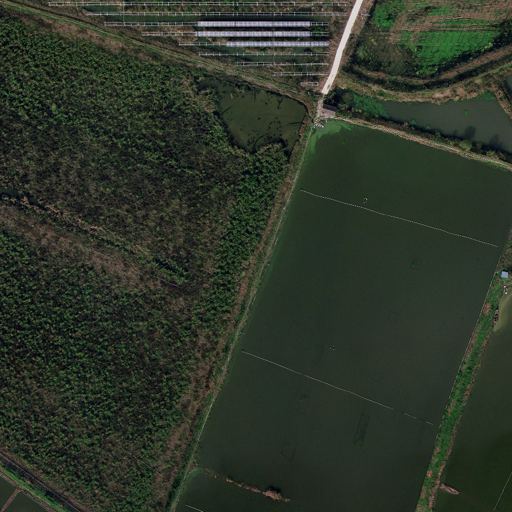

In [13]:
import os
import numpy as np
from PIL import Image

# Busco la primera imagen del dataset (las que no son máscaras)
carpeta = "/lakehouse/default/Files/datasets/jiang_pv"
for raiz, _, archivos in os.walk(carpeta):
    imagenes = sorted(a for a in archivos if a.endswith(".bmp") and not a.endswith("_label.bmp"))
    if imagenes:
        ruta_img = os.path.join(raiz, imagenes[0])
        break

# Su máscara tiene el mismo nombre acabado en _label
ruta_mascara = ruta_img.replace(".bmp", "_label.bmp")

imagen = Image.open(ruta_img).convert("RGB")
mascara = np.array(Image.open(ruta_mascara).convert("L"))

# % real de paneles = píxeles marcados en la máscara / total de píxeles
pct_real = (mascara > 0).mean() * 100
print(ruta_img)
print(f"% de paneles según la máscara: {pct_real:.1f} %")
display(imagen.resize((512, 512)))

In [12]:
MODELO = "gemini-3.5-flash"

prompt = """Esta es una imagen aérea (ortofoto) de una parcela con una planta fotovoltaica.
Clasifica la parcela en una de estas fases de obra:
terreno_sin_tocar, movimiento_de_tierras, estructuras_sin_paneles, paneles_instalados.
Estima también el porcentaje de la superficie de la imagen cubierta por paneles solares.
Responde solo con un JSON así: {"fase": "...", "pct_paneles": 0-100}"""

# Le pido que conteste directamente en JSON para poder guardarlo luego en una tabla
respuesta = client.models.generate_content(
    model=MODELO,
    contents=[imagen, prompt],
    config={"response_mime_type": "application/json"},
)
print(respuesta.text)

StatementMeta(, e28f9f43-5ec1-434f-874d-de4215f454dd, 20, Finished, Available, Finished, False)

{
  "fase": "paneles_instalados",
  "pct_paneles": 1
}
